# 4. Strike grid and Guardian pause cap
BLUEPRINT §3.3 and §10 (2026-10-23).

In [1]:
import csv
from pathlib import Path
OUT = Path("../out")

def load(name):
    """rows of out/<name>.csv as dicts (numbers stay strings; use f())"""
    with open(OUT / f"{name}.csv") as fh:
        return list(csv.DictReader(fh))

def f(x):
    try:
        return float(x)
    except (TypeError, ValueError):
        return x

def show(rows, cols=None, limit=40, where=None):
    """print rows as an aligned table"""
    if where:
        rows = [r for r in rows if where(r)]
    rows = rows[:limit]
    if not rows:
        print("(no rows)"); return
    cols = cols or list(rows[0].keys())
    def fmt(v):
        try:
            x = float(v)
            return f"{x:,.4g}" if abs(x) < 1e6 else f"{x:,.0f}"
        except (TypeError, ValueError):
            return str(v)
    cells = [[fmt(r.get(c, "")) for c in cols] for r in rows]
    w = [max(len(c), *(len(row[i]) for row in cells)) for i, c in enumerate(cols)]
    print(" | ".join(c.ljust(w[i]) for i, c in enumerate(cols)))
    print("-+-".join("-" * x for x in w))
    for row in cells:
        print(" | ".join(v.rjust(w[i]) for i, v in enumerate(row)))

def svg(name):
    """display a pre-rendered chart from out/plots"""
    p = OUT / "plots" / name
    try:
        from IPython.display import SVG, display
        display(SVG(filename=str(p)))
    except Exception:
        print(f"[chart: {p}]")

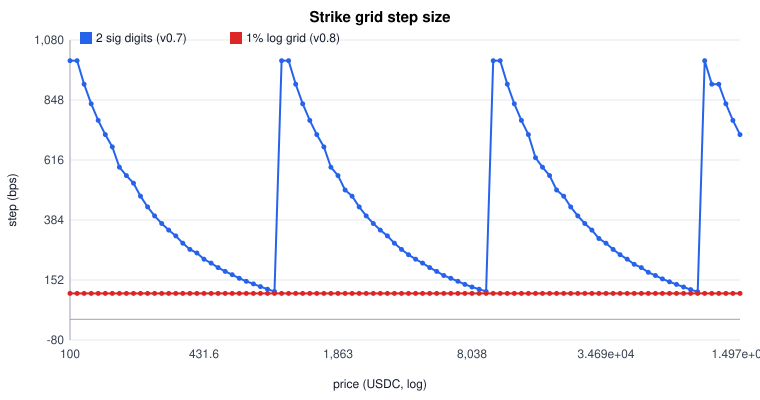

In [2]:
svg("grid_steps.svg")  # strike grid step size

In [3]:
show(load("grid"), limit=20, where=lambda r: f(r["price_usdc"]) > 1000)

price_usdc | sig2_step_bps | log_step_bps | sig2_nearest | log_nearest
-----------+---------------+--------------+--------------+------------
     1,006 |         1,000 |          100 |        1,000 |       1,003
     1,087 |         1,000 |          100 |        1,000 |       1,086
     1,174 |         909.1 |          100 |        1,100 |       1,176
     1,268 |         833.3 |          100 |        1,200 |       1,274
     1,369 |         769.2 |          100 |        1,300 |       1,366
     1,479 |         714.3 |          100 |        1,400 |       1,479
     1,597 |         666.7 |          100 |        1,500 |       1,601
     1,725 |         588.2 |          100 |        1,700 |       1,717
     1,863 |         555.6 |          100 |        1,800 |       1,859
     2,012 |           500 |          100 |        2,000 |       2,013
     2,172 |         476.2 |          100 |        2,100 |       2,180
     2,346 |         434.8 |          100 |        2,300 |       2,337
     2

The 2-digit grid steps between 1 % and 10 % and jumps to 10 % exactly where LST ratios cross 1.0; the log grid is 1 % everywhere.

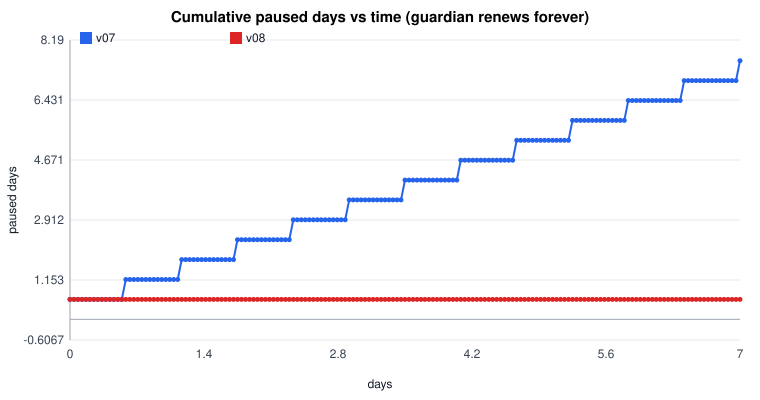

In [4]:
svg("pause.svg")  # cumulative paused days under renewals

In [5]:
p = load("pause"); show([r for r in p if r["block"] == "604800"])

rules | block     | paused | paused_total_blocks | renewals_accepted | renewals_rejected
------+-----------+--------+---------------------+-------------------+------------------
  v07 | 6.048e+05 |   true |           6.552e+05 |                13 |                 0
  v08 | 6.048e+05 |  false |            5.04e+04 |                 1 |             5,546
